# False Positive Analysis
## Objective
- find out WHY the detector falsely flags human-written text as AI-generated
- test the trained model on outside/new human-written text samples (not from our training data) to find out WHY it falsely flags genuine human writing as AI-generated

1. Filter rows where author=human and predicted=ai (false positives)
2. Compare these false positives against correctly-classified human text (author=human, predicted=human) — are they shorter, more formal, less "bursty" in sentence length, from a specific domain?
3. Pull 3-5 actual example sentences from the false positives to quote as evidence.
4. Create a simple bar chart or table showing the difference in features (Use teammate 2's (objective 2 extract_features() from feature engineering, use that; otherwise just use word count/sentence variance).
5. Summarize the pattern in 2-3 sentences I can put directly into my report section.
6. Load our trained model and vectorizer with pickle

- already has results/test_predictions.csv from your training run, just load that CSV and filter

**First analyse test_prediction.csv why our model testing flagging human text as AI then use the data/processed/Detect_hum benchmark and paste those text into our model and test how our model prediciting and compare with other models prediction(Detect_hum/results.csv)**

In [68]:

!pip install pandas



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [69]:
import pandas as pd

df = pd.read_csv("../results/test_predictions.csv")

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()

Shape: (13628, 7)
Columns: ['text', 'author', 'gen_source', 'domain', 'source_dataset', 'split', 'predicted']


,text,author,gen_source,domain,source_dataset,split,predicted
0,"A collection of characters with a same design style, such as letters, numbers, punctuation, and symbols, is called a typeface. Despite the fact that the terminology are different, it is frequently misidentified as a ""font"" and refers to the artistic or visual representation of text. Like Helvetica, Times New Roman, or Futura, a typeface is basically a family or design that contains variations like bold, italic, light, condensed, and other styles within that family.Each variation is considered a font within the typeface family. For example, Helvetica Bold Italic at 12pt is a font, while Helvetica is the typeface. Typefaces are created by type designers and are used to communicate tone, emotion, brand identity, and visual hierarchy in any design. Some typefaces are formal and traditional, evoking feelings of authority or reliability—commonly used in legal or academic contexts—while others may be modern, playful, or expressive, suited for creative, casual, or artistic projects. Typefaces are categorized into several styles, such as serif, sans-serif, slab serif, script, and display, each with its own unique aesthetic and functional qualities. The choice of a typeface affects not only the appearance but also the readability and accessibility of content, especially in digital formats where screen resolution and scalability matter. Designers often consider a typeface’s x-height, stroke contrast, width, and overall proportion when selecting it for use in various mediums like websites, magazines, apps, packaging, or signage.A typeface's past can also have cultural or historical significance; for example, Helvetica's connection to modernist design or Garamond's to classic literature. In general, a typeface is much more than just a letter style; it is an essential design tool that affects how an audience experiences, comprehends, and reacts to content in a variety of visual contexts.",ai,ai-generated and ai-refined and human-written,unknown,txd_22,test,ai
1,"Paddy farming refers to the specialized cultivation of rice, the staple food crop for more than half of the world’s population, especially across Asia. Paddy fields are flat, low-lying plots surrounded by earthen embankments called bunds, designed to retain water and create shallow flooded conditions ideal for rice plants. Flooding is essential in paddy farming as it helps suppress weeds, control pests, and provide a consistent water supply for the rice crop during its growing period. The cultivation process begins with land preparation, including plowing and leveling the field, followed by transplanting young rice seedlings or direct seeding into the flooded paddies. Water management is critical, with water levels maintained at about 5 to 10 centimeters throughout much of the growing cycle to ensure optimum growth and yield. Paddy farming thrives in regions with warm temperatures, high humidity, and abundant rainfall or irrigation facilities. Although labor-intensive and requiring substantial water resources, paddy farming remains one of the most productive methods of rice cultivation. However, flooded paddies are known to release methane, a potent greenhouse gas, contributing to global climate change. To reduce water consumption and greenhouse gas emissions, farmers are increasingly adopting sustainable practices such as alternate wetting and drying irrigation methods, improved rice varieties, and integrated pest management. Paddy farming supports millions of smallholder farmers and forms the backbone of food security in many rice-dependent countries, making it an essential agricultural practice worldwide.",ai,chatgpt,unknown,txd_22,test,ai
2,"Fishes are aquatic vertebrates characterized by several distinctive features that enable them to live efficiently in water. Their body is typically divided into three main parts: the head, trunk, and tail, although these divisions may not always be externally obvious. They po

In [70]:
# False Positives:
# Actual = human
# Predicted = ai

false_positives = df[
    (df["author"].str.lower() == "human") &
    (df["predicted"].str.lower() == "ai")
].copy()

# Correctly classified human texts
correct_human = df[
    (df["author"].str.lower() == "human") &
    (df["predicted"].str.lower() == "human")
].copy()

print("False Positive count:", len(false_positives))
print("Correct Human count:", len(correct_human))

False Positive count: 734
Correct Human count: 702


In [71]:
print("===== FALSE POSITIVE HUMAN TEXTS =====")

for i, text in enumerate(false_positives["text"].head(5), 1):
    print(f"\n--- Example {i} ---")
    print(text)
    

===== FALSE POSITIVE HUMAN TEXTS =====

--- Example 1 ---
used for creating realistic face animations of virtual actors for applications in computer animation, film, and video games. Creation of convincing facial animation is a challenging task due to the highly nonrigid nature of the face and the complexity of detecting and tracking the facial landmarks accurately and efficiently in uncontrolled environments. It involves facial deformation and fine-grained details. In addition, the uncanny valley effect [1] indicates that people are extremely capable of identifying subtle artifacts in facial appearance. Hence, animators need to make a tremendous amount of effort to localize high quality facial landmarks. To reduce the amount of manual labor, an ideal face capture solution should automatically provide the facial shape (landmarks) with high performance given reasonable quality input videos.

--- Example 2 ---
Climatic change is considered likely to increase runoff in the higher latitude

In [72]:
false_positives.to_csv(
    "../results/false_positives.csv",
    index=False
)

print("False positives saved successfully.")

False positives saved successfully.


In [73]:
print(df.columns.tolist())

['text', 'author', 'gen_source', 'domain', 'source_dataset', 'split', 'predicted']


In [74]:
# Human text incorrectly predicted as AI
false_positives = df[
    (df["author"].str.lower() == "human") &
    (df["predicted"].str.lower() == "ai")
].copy()

# Human text correctly predicted as Human
correct_human = df[
    (df["author"].str.lower() == "human") &
    (df["predicted"].str.lower() == "human")
].copy()

print("False Positive count:", len(false_positives))
print("Correct Human count:", len(correct_human))

False Positive count: 734
Correct Human count: 702


In [75]:
!pip install scikit-learn



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [76]:
print("Author values:")
print(df["author"].value_counts())

print("\nPredicted values:")
print(df["predicted"].value_counts())

Author values:
author
ai       12192
human     1436
Name: count, dtype: int64

Predicted values:
predicted
ai       12843
human      785
Name: count, dtype: int64


In [77]:
false_positives = df[
    (df["author"].str.lower() == "human") &
    (df["predicted"].str.lower() == "ai")
].copy()

print("False Positive count:", len(false_positives))


False Positive count: 734


In [78]:
correct_human = df[
    (df["author"].str.lower() == "human") &
    (df["predicted"].str.lower() == "human")
].copy()

print("Correct Human count:", len(correct_human))

Correct Human count: 702


In [79]:
print("False Positives by domain:")
print(false_positives["domain"].value_counts())

print("\nCorrect Human by domain:")
print(correct_human["domain"].value_counts())

False Positives by domain:
domain
unknown                                         509
Genetics and Genomics                            34
Computer Science and Artificial Intelligence     30
Social Sciences and Humanities                   29
Climate Science and Environmental Studies        28
Astrophysics and Astronomy                       26
Mathematics and Statistics                       16
Neuroscience and Psychology                      16
Medical Research and Healthcare                  15
Natural Language Processing                      14
Materials science and engineering                14
Materials Science and Engineering                 3
Name: count, dtype: int64

Correct Human by domain:
domain
unknown                                         124
Astrophysics and Astronomy                       87
Computer Science and Artificial Intelligence     80
Social Sciences and Humanities                   58
Genetics and Genomics                            55
Natural Language Proces

In [80]:
false_positives["word_count"] = (
    false_positives["text"]
    .fillna("")
    .str.split()
    .str.len()
)

correct_human["word_count"] = (
    correct_human["text"]
    .fillna("")
    .str.split()
    .str.len()
)

In [81]:
print("False Positive average word count:",
      false_positives["word_count"].mean())

print("Correct Human average word count:",
      correct_human["word_count"].mean())

False Positive average word count: 262.6907356948229
Correct Human average word count: 193.64102564102564


In [82]:
print("False Positive median:",
      false_positives["word_count"].median())

print("Correct Human median:",
      correct_human["word_count"].median())

False Positive median: 264.0
Correct Human median: 192.0


In [83]:
import re
import numpy as np

def sentence_features(text):
    text = str(text)

    sentences = re.split(r'[.!?]+', text)

    sentences = [
        s.strip()
        for s in sentences
        if s.strip()
    ]

    if len(sentences) == 0:
        return pd.Series({
            "sentence_count": 0,
            "avg_sentence_length": 0,
            "sentence_length_variance": 0
        })

    lengths = [
        len(sentence.split())
        for sentence in sentences
    ]

    return pd.Series({
        "sentence_count": len(sentences),
        "avg_sentence_length": np.mean(lengths),
        "sentence_length_variance": np.var(lengths)
    })

In [84]:
fp_sentence_features = false_positives["text"].apply(sentence_features)

ch_sentence_features = correct_human["text"].apply(sentence_features)

In [85]:
false_positives = pd.concat(
    [false_positives, fp_sentence_features],
    axis=1
)

correct_human = pd.concat(
    [correct_human, ch_sentence_features],
    axis=1
)

In [86]:
comparison = pd.DataFrame({
    "Feature": [
        "Word Count",
        "Sentence Count",
        "Average Sentence Length",
        "Sentence Length Variance"
    ],
    "False Positive (Human → AI)": [
        false_positives["word_count"].mean(),
        false_positives["sentence_count"].mean(),
        false_positives["avg_sentence_length"].mean(),
        false_positives["sentence_length_variance"].mean()
    ],
    "Correct Human (Human → Human)": [
        correct_human["word_count"].mean(),
        correct_human["sentence_count"].mean(),
        correct_human["avg_sentence_length"].mean(),
        correct_human["sentence_length_variance"].mean()
    ]
})

comparison

,Feature,False Positive (Human → AI),Correct Human (Human → Human)
0,Word Count,262.690736,193.641026
1,Sentence Count,11.107629,9.712251
2,Average Sentence Length,24.395202,20.689876
3,Sentence Length Variance,115.426021,111.518353


In [87]:
print(false_positives[["text", "domain"]].head(10))

In [88]:
print(correct_human[["text", "domain"]].head(10))

In [89]:
examples = false_positives[
    ["text", "domain", "source_dataset"]
].sample(5, random_state=42)

examples

,text,domain,source_dataset
10209,"Sampling is the act, process, or technique of selecting a suitable sample, or a representative part of a population for the purpose of determining parameters or characteristics of the whole population. As researching an entire population is rarely feasible, almost all social research is conducted on a sample rather than the entire population, and researchers must sample only a portion of the population to generate results capable of being generalized from the sample to the population. The selected group is referred to as a sample, and the entire group from which the sample is drawn is the population. Sampling plays a key role in the field of statistics and research by providing analysts an opportunity estimate population parameters, testing hypothesis, and making prediction without analyzing all members of the population from which sample has been created. In order for sampling to be successful and produce accurate results, the sample must be representative of the population, or those characteristics that describe the population, must be proportional to the sample. There are two major types of sampling: Probability Sampling A sample chosen from a larger population by using a chance process or a random number generator in which each member of the population has a known probability of being chosen and non-probability sampling in which no probability is attached to members of the population as a basis for selecting them. Some of the probability sampling techniques are, simple random sampling, stratified sampling, cluster sampling and systematic sampling, and each of these has their own methodologies and applications. Non-probability techniques are convenience, quota and purposive. Sampling is closely related to ideas like sampling distribution, standard error, and confidence intervals which are used to quantify the uncertainty and variability of estimates coming from it. The sample size is an essential factor in such case as well; the larger the sample, the more accurate the estimates, though such collection may require more resources. Inferior sampling may result in bias, which decreases the validity of inference. Sampling is applicable to a variety of fields such as opinion polling, medical research, business market and quality control. At the end of the day, sampling allows investigators and decision makers to study diverse populations to quickly draw inferences that may be applicable to broader groups.",unknown,txd_22
656,"The growth and the spread of the Ottoman Empire started from the late 13th century, where the former began its expansion in the hands of the its first leader, Osman I and his successors. At first, the Ottomans were just one of the many Turkish states in Anatolia, but they survived and took shape into a dynasty because of the labour organization and unique military tactics and power. An elite infantry corps, the Janissaries, created by the Dev?irme (the forced recruitment of Christian children), was the loyal and disciplined base. Through the use of gunpowder (which was invented in the east specifically as a siege weapon) and effectively ending the siege in the Balkans, the Ottomans captured both the Balkans' strategically-most important city, Byzantine Thessaloniki, in 1387, and the Byzantine capital, Constantinople in 1453. It was a cataclysmic event, the fall of Constantinople in 1453 at the hands of Mehmed II, which resulted in the extinction of the Byzantine Empire and made Istanbul a vibrant cultural and economic center. The victory gave the Ottomans control of trade routes between Europe and Asia. The Ottomans rose to dominance under Suleiman the Magnificent in the 16th century when they conquered Baghdad, Rhodes and portions of Hungary, including Belgrade, and made the empire a global powerhouse that spanned three continents — Europe, Asia and Africa. Ottoman rule integrated a highly centralized system with moderate provincial autonomy, much to the benefit of both T

In [90]:
pd.set_option("display.max_colwidth", None)

examples

,text,domain,source_dataset
10209,"Sampling is the act, process, or technique of selecting a suitable sample, or a representative part of a population for the purpose of determining parameters or characteristics of the whole population. As researching an entire population is rarely feasible, almost all social research is conducted on a sample rather than the entire population, and researchers must sample only a portion of the population to generate results capable of being generalized from the sample to the population. The selected group is referred to as a sample, and the entire group from which the sample is drawn is the population. Sampling plays a key role in the field of statistics and research by providing analysts an opportunity estimate population parameters, testing hypothesis, and making prediction without analyzing all members of the population from which sample has been created. In order for sampling to be successful and produce accurate results, the sample must be representative of the population, or those characteristics that describe the population, must be proportional to the sample. There are two major types of sampling: Probability Sampling A sample chosen from a larger population by using a chance process or a random number generator in which each member of the population has a known probability of being chosen and non-probability sampling in which no probability is attached to members of the population as a basis for selecting them. Some of the probability sampling techniques are, simple random sampling, stratified sampling, cluster sampling and systematic sampling, and each of these has their own methodologies and applications. Non-probability techniques are convenience, quota and purposive. Sampling is closely related to ideas like sampling distribution, standard error, and confidence intervals which are used to quantify the uncertainty and variability of estimates coming from it. The sample size is an essential factor in such case as well; the larger the sample, the more accurate the estimates, though such collection may require more resources. Inferior sampling may result in bias, which decreases the validity of inference. Sampling is applicable to a variety of fields such as opinion polling, medical research, business market and quality control. At the end of the day, sampling allows investigators and decision makers to study diverse populations to quickly draw inferences that may be applicable to broader groups.",unknown,txd_22
656,"The growth and the spread of the Ottoman Empire started from the late 13th century, where the former began its expansion in the hands of the its first leader, Osman I and his successors. At first, the Ottomans were just one of the many Turkish states in Anatolia, but they survived and took shape into a dynasty because of the labour organization and unique military tactics and power. An elite infantry corps, the Janissaries, created by the Dev?irme (the forced recruitment of Christian children), was the loyal and disciplined base. Through the use of gunpowder (which was invented in the east specifically as a siege weapon) and effectively ending the siege in the Balkans, the Ottomans captured both the Balkans' strategically-most important city, Byzantine Thessaloniki, in 1387, and the Byzantine capital, Constantinople in 1453. It was a cataclysmic event, the fall of Constantinople in 1453 at the hands of Mehmed II, which resulted in the extinction of the Byzantine Empire and made Istanbul a vibrant cultural and economic center. The victory gave the Ottomans control of trade routes between Europe and Asia. The Ottomans rose to dominance under Suleiman the Magnificent in the 16th century when they conquered Baghdad, Rhodes and portions of Hungary, including Belgrade, and made the empire a global powerhouse that spanned three continents — Europe, Asia and Africa. Ottoman rule integrated a highly centralized system with moderate provincial autonomy, much to the benefit of both T

In [91]:
print("False Positives by source dataset:")
print(false_positives["source_dataset"].value_counts())

print("\nCorrect Human by source dataset:")
print(correct_human["source_dataset"].value_counts())

False Positives by source dataset:
source_dataset
txd_22    509
ai_h      225
Name: count, dtype: int64

Correct Human by source dataset:
source_dataset
ai_h      470
txd_22    124
gpt_t2    108
Name: count, dtype: int64


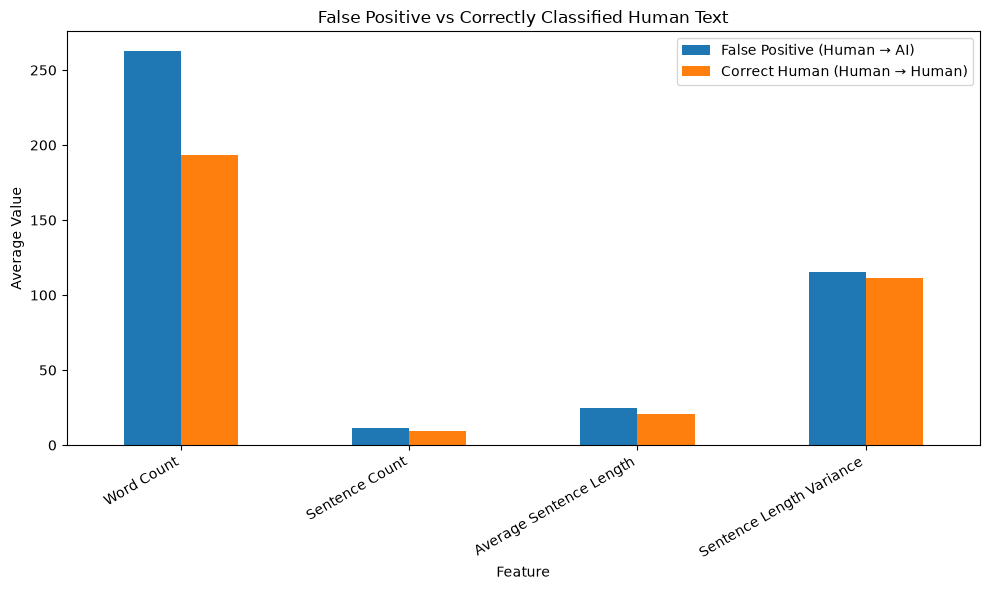

In [92]:
import matplotlib.pyplot as plt

comparison.plot(
    x="Feature",
    y=[
        "False Positive (Human → AI)",
        "Correct Human (Human → Human)"
    ],
    kind="bar",
    figsize=(10, 6)
)

plt.title("False Positive vs Correctly Classified Human Text")
plt.ylabel("Average Value")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [93]:
import sys
!{sys.executable} -m pip install matplotlib


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [94]:
import pickle

with open("../models/baseline_model.pkl", "rb") as f:
    model = pickle.load(f)

with open("../models/tfidf_vectorizer.pkl", "rb") as f:
    vectorizer = pickle.load(f)

print("Model loaded successfully!")
print("Model type:", type(model))

print("Vectorizer loaded successfully!")
print("Vectorizer type:", type(vectorizer))

Model loaded successfully!
Model type: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Vectorizer loaded successfully!
Vectorizer type: <class 'sklearn.feature_extraction.text.TfidfVectorizer'>


In [95]:
new_text = """
I went to the library yesterday to complete my university assignment.
The place was quiet, so I was able to concentrate on my work.
After finishing the assignment, I went home in the evening.
"""

# Convert text using the same TF-IDF vectorizer
X_new = vectorizer.transform([new_text])

# Predict
prediction = model.predict(X_new)

print("Prediction:", prediction[0])

Prediction: human


In [96]:
if hasattr(model, "predict_proba"):
    probabilities = model.predict_proba(X_new)

    print("Classes:", model.classes_)
    print("Probabilities:", probabilities[0])

Classes: ['ai' 'human']
Probabilities: [0.08252097 0.91747903]


In [97]:
new_samples = [
    "I went to the library yesterday to complete my university assignment.",
    "My friend called me in the evening and we discussed our project work.",
    "The weather was very hot today, so I stayed at home and studied.",
    "I submitted my assignment before the deadline and then went for lunch.",
    "Our lecturer explained the topic again because some students did not understand it."
]

X_new = vectorizer.transform(new_samples)
predictions = model.predict(X_new)

for i, (text, prediction) in enumerate(zip(new_samples, predictions), 1):
    print(f"\nSample {i}")
    print("Text:", text)
    print("Prediction:", prediction)


Sample 1
Text: I went to the library yesterday to complete my university assignment.
Prediction: ai

Sample 2
Text: My friend called me in the evening and we discussed our project work.
Prediction: ai

Sample 3
Text: The weather was very hot today, so I stayed at home and studied.
Prediction: human

Sample 4
Text: I submitted my assignment before the deadline and then went for lunch.
Prediction: ai

Sample 5
Text: Our lecturer explained the topic again because some students did not understand it.
Prediction: ai


In [98]:
import pandas as pd

abstracts_df = pd.read_csv("../data/processed/Detect_hum/abstracts.csv")

print("Shape:", abstracts_df.shape)
print("Columns:", abstracts_df.columns.tolist())

abstracts_df.head()

Shape: (295, 14)
Columns: ['No', 'Journal', 'Vol', 'Year', 'Category', 'Country', 'Status', 'DOI', 'Title', 'Abstract', 'AI-Generated ChatGPT', 'AI-Generated Gemini', 'AI-Assisted ChatGPT', 'AI-Assisted Gemini']


,No,Journal,Vol,Year,Category,Country,Status,DOI,Title,Abstract,AI-Generated ChatGPT,AI-Generated Gemini,AI-Assisted ChatGPT,AI-Assisted Gemini
0,1,Sociology,55.0,2021.0,Social Sciences,Hungary,Non-Native,https://doi-org.proxy.library.stonybrook.edu/10.1177/0038038520941690,â€˜We Are That In-Between Nationâ€™: Discourses of Deservingness of Hungarian Migrants Working in Institutions of Refugee Accommodation in Germany,"The article elaborates on the role of deservingness discourses in regulating membership of non-citizen groups in Germany. Specifically, it focuses on Hungarians working or volunteering in institutions of refugee accommodation in Germany. It asks how personal migration experience and migrant statuses and identities of Hungarian workers are mobilised when recreating discourses of refugee-deservingness. Performance expectations on refugees related to education and employment evoked references to similarities of migration experience, strengthening an empathetic perspective towards refugee clients and students. Deservingness frameworks related to culture were more ambiguous. A â€˜mission civilisatriceâ€™, that is educating Muslim Others to European, non-Muslim ways of behaving and thinking, often tied to gender relations, was paralleled by a continuous attempt to challenge and dismantle such discourses of difference and disciplining. These ambivalences of empathetic identification and disciplinary racialisation draw the contours of a characteristic place of (Hungarian) migrant workers in the governance of refugee accommodation in Germany.","This article investigates how Hungarian migrants employed at refugee accommodation facilities in Germany construct discourses of deservingnessâ€”both for themselves and for the asylum seekers they serve. Drawing on in-depth interviews and ethnographic observations, the study explores how Hungarian staff navigate their own precarious positions as â€œin-betweenâ€ migrants, simultaneously facing challenges in the German labor market and exercising authority over refugees from diverse backgrounds. Findings reveal that these workers often articulate a sense of â€œsecond-classâ€ status, rooted in their experiences of discrimination, while also claiming moral legitimacy through their comparative advantage in language skills, cultural mediation, and personal empathy. Yet they sometimes reproduce exclusionary narratives about asylum seekers, invoking cultural hierarchies and neoliberal ideals of self-sufficiency. The article argues that these discourses of deservingness illuminate the tensions between economic rationales, humanitarian impulses, and nationalistic sentiments in an evolving European migration landscape. Ultimately, the study highlights how â€œin-betweenâ€ migrants engage in complex moral boundary work, reshaping perceptions of who merits rights, resources, and recognition within refugee accommodation institutions.","This article examines the discursive construction of deservingness among Hungarian migrants working in German refugee accommodation centers. Situated within the context of the European ""refugee crisis"" and rising anti-immigrant sentiment, the study analyzes how Hungarian workers navigate their own positionality as migrants while simultaneously engaging in the management and care of refugees. Drawing on ethnographic fieldwork and interviews, we identify a dominant discourse of ""in-betweenness,"" where Hungarians position themselves between ""undeserving"" refugees and ""deserving"" Germans. This positioning is achieved through narratives that emphasize their own hard work, integration efforts, and perceived cultural proximity to German society, while simultaneously distancing themselves from refugees based on perceived cultural differences and lack of effort. The study contributes to the literature on migration and deservingness by highlighting the complex and often contradictory ways in which migrants negotiate their own identities and moral worth within hie

In [99]:
print(abstracts_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 295 entries, 0 to 294
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   No                    295 non-null    int64  
 1   Journal               72 non-null     str    
 2   Vol                   72 non-null     float64
 3   Year                  72 non-null     float64
 4   Category              72 non-null     str    
 5   Country               72 non-null     str    
 6   Status                72 non-null     str    
 7   DOI                   72 non-null     str    
 8   Title                 72 non-null     str    
 9   Abstract              72 non-null     str    
 10  AI-Generated ChatGPT  72 non-null     str    
 11  AI-Generated Gemini   72 non-null     str    
 12  AI-Assisted ChatGPT   72 non-null     str    
 13  AI-Assisted Gemini    72 non-null     str    
dtypes: float64(2), int64(1), str(11)
memory usage: 32.4 KB
None


In [100]:
for col in abstracts_df.columns:
    print(f"\n--- {col} ---")
    print(abstracts_df[col].head())


--- No ---
0    1
1    2
2    3
3    4
4    5
Name: No, dtype: int64

--- Journal ---
0                                    Sociology
1                                    SAGE Open
2                        Computers & Education
3    British Journal of Educational Technology
4                                  IEEE Access
Name: Journal, dtype: str

--- Vol ---
0     55.0
1      1.0
2    172.0
3     52.0
4      9.0
Name: Vol, dtype: float64

--- Year ---
0    2021.0
1    2021.0
2    2021.0
3    2020.0
4    2021.0
Name: Year, dtype: float64

--- Category ---
0             Social Sciences
1             Social Sciences
2           Interdisciplinary
3           Interdisciplinary
4    Technology & Engineering
Name: Category, dtype: str

--- Country ---
0      Hungary
1    Australia
2          USA
3       Taiwan
4        Japan
Name: Country, dtype: str

--- Status ---
0    Non-Native
1        Native
2        Native
3    Non-Native
4    Non-Native
Name: Status, dtype: str

--- DOI ---
0    https

In [101]:
text_column = "text"

In [102]:
import pickle

with open("../models/baseline_model.pkl", "rb") as f:
    model = pickle.load(f)

with open("../models/tfidf_vectorizer.pkl", "rb") as f:
    vectorizer = pickle.load(f)

print("Model:", type(model))
print("Vectorizer:", type(vectorizer))

Model: <class 'sklearn.linear_model._logistic.LogisticRegression'>
Vectorizer: <class 'sklearn.feature_extraction.text.TfidfVectorizer'>


In [103]:
import pandas as pd

abstracts_df = pd.read_csv("../data/processed/Detect_hum/abstracts.csv")

print("Columns in abstracts.csv:")
print(abstracts_df.columns.tolist())

print("\nFirst 5 rows:")
display(abstracts_df.head())

Columns in abstracts.csv:
['No', 'Journal', 'Vol', 'Year', 'Category', 'Country', 'Status', 'DOI', 'Title', 'Abstract', 'AI-Generated ChatGPT', 'AI-Generated Gemini', 'AI-Assisted ChatGPT', 'AI-Assisted Gemini']

First 5 rows:


,No,Journal,Vol,Year,Category,Country,Status,DOI,Title,Abstract,AI-Generated ChatGPT,AI-Generated Gemini,AI-Assisted ChatGPT,AI-Assisted Gemini
0,1,Sociology,55.0,2021.0,Social Sciences,Hungary,Non-Native,https://doi-org.proxy.library.stonybrook.edu/10.1177/0038038520941690,â€˜We Are That In-Between Nationâ€™: Discourses of Deservingness of Hungarian Migrants Working in Institutions of Refugee Accommodation in Germany,"The article elaborates on the role of deservingness discourses in regulating membership of non-citizen groups in Germany. Specifically, it focuses on Hungarians working or volunteering in institutions of refugee accommodation in Germany. It asks how personal migration experience and migrant statuses and identities of Hungarian workers are mobilised when recreating discourses of refugee-deservingness. Performance expectations on refugees related to education and employment evoked references to similarities of migration experience, strengthening an empathetic perspective towards refugee clients and students. Deservingness frameworks related to culture were more ambiguous. A â€˜mission civilisatriceâ€™, that is educating Muslim Others to European, non-Muslim ways of behaving and thinking, often tied to gender relations, was paralleled by a continuous attempt to challenge and dismantle such discourses of difference and disciplining. These ambivalences of empathetic identification and disciplinary racialisation draw the contours of a characteristic place of (Hungarian) migrant workers in the governance of refugee accommodation in Germany.","This article investigates how Hungarian migrants employed at refugee accommodation facilities in Germany construct discourses of deservingnessâ€”both for themselves and for the asylum seekers they serve. Drawing on in-depth interviews and ethnographic observations, the study explores how Hungarian staff navigate their own precarious positions as â€œin-betweenâ€ migrants, simultaneously facing challenges in the German labor market and exercising authority over refugees from diverse backgrounds. Findings reveal that these workers often articulate a sense of â€œsecond-classâ€ status, rooted in their experiences of discrimination, while also claiming moral legitimacy through their comparative advantage in language skills, cultural mediation, and personal empathy. Yet they sometimes reproduce exclusionary narratives about asylum seekers, invoking cultural hierarchies and neoliberal ideals of self-sufficiency. The article argues that these discourses of deservingness illuminate the tensions between economic rationales, humanitarian impulses, and nationalistic sentiments in an evolving European migration landscape. Ultimately, the study highlights how â€œin-betweenâ€ migrants engage in complex moral boundary work, reshaping perceptions of who merits rights, resources, and recognition within refugee accommodation institutions.","This article examines the discursive construction of deservingness among Hungarian migrants working in German refugee accommodation centers. Situated within the context of the European ""refugee crisis"" and rising anti-immigrant sentiment, the study analyzes how Hungarian workers navigate their own positionality as migrants while simultaneously engaging in the management and care of refugees. Drawing on ethnographic fieldwork and interviews, we identify a dominant discourse of ""in-betweenness,"" where Hungarians position themselves between ""undeserving"" refugees and ""deserving"" Germans. This positioning is achieved through narratives that emphasize their own hard work, integration efforts, and perceived cultural proximity to German society, while simultaneously distancing themselves from refugees based on perceived cultural differences and lack of effort. The study contributes to the literature on migration and deservingness by highlighting the complex and often contradictory ways in which migrants negotiate their own identities and moral worth within hie

In [104]:
output_path = "../data/processed/Detect_hum/abstracts_predictions.csv"

abstracts_df.to_csv(output_path, index=False)

print("Saved successfully:", output_path)

Saved successfully: ../data/processed/Detect_hum/abstracts_predictions.csv


In [105]:
results_df = pd.read_csv("../data/processed/Detect_hum/results.csv")

print("Shape:", results_df.shape)
print("Columns:", results_df.columns.tolist())

results_df.head()

Shape: (1080, 9)
Columns: ['id', 'article', 'category', 'status', 'text', 'llm', 'tool', 'score', 'label']


,id,article,category,status,text,llm,tool,score,label
0,1,1,social,non-native,original,NaN,GPTZero,0.00%,human
1,2,2,social,native,original,NaN,GPTZero,0.00%,human
2,3,3,interdisciplinary,native,original,NaN,GPTZero,0.00%,human
3,4,4,interdisciplinary,non-native,original,NaN,GPTZero,0.00%,human
4,5,5,tech&engineering,non-native,original,NaN,GPTZero,1.00%,human


In [106]:
results_df = pd.read_csv("../data/processed/Detect_hum/results.csv")

print("Shape:", results_df.shape)
print("Columns:", results_df.columns.tolist())

results_df.head()

Shape: (1080, 9)
Columns: ['id', 'article', 'category', 'status', 'text', 'llm', 'tool', 'score', 'label']


,id,article,category,status,text,llm,tool,score,label
0,1,1,social,non-native,original,NaN,GPTZero,0.00%,human
1,2,2,social,native,original,NaN,GPTZero,0.00%,human
2,3,3,interdisciplinary,native,original,NaN,GPTZero,0.00%,human
3,4,4,interdisciplinary,non-native,original,NaN,GPTZero,0.00%,human
4,5,5,tech&engineering,non-native,original,NaN,GPTZero,1.00%,human


In [107]:
import pandas as pd

path = "../data/processed/Detect_hum/abstracts.csv"

abstracts_df = pd.read_csv(path)

print("CSV loaded successfully")
print("Shape:", abstracts_df.shape)
print("Column names:", list(abstracts_df.columns))

CSV loaded successfully
Shape: (295, 14)
Column names: ['No', 'Journal', 'Vol', 'Year', 'Category', 'Country', 'Status', 'DOI', 'Title', 'Abstract', 'AI-Generated ChatGPT', 'AI-Generated Gemini', 'AI-Assisted ChatGPT', 'AI-Assisted Gemini']


In [108]:
print("Abstracts columns:")
print(abstracts_df.columns.tolist())

print("\nResults columns:")
print(results_df.columns.tolist())

Abstracts columns:
['No', 'Journal', 'Vol', 'Year', 'Category', 'Country', 'Status', 'DOI', 'Title', 'Abstract', 'AI-Generated ChatGPT', 'AI-Generated Gemini', 'AI-Assisted ChatGPT', 'AI-Assisted Gemini']

Results columns:
['id', 'article', 'category', 'status', 'text', 'llm', 'tool', 'score', 'label']


In [109]:
import pandas as pd
import os

print("Current directory:")
print(os.getcwd())

path = "../data/processed/Detect_hum/abstracts.csv"

print("\nFile exists:", os.path.exists(path))

abstracts_df = pd.read_csv(path)

print("\nCSV loaded!")
print("Shape:", abstracts_df.shape)
print("Columns:")
print(list(abstracts_df.columns))

Current directory:
c:\Users\User\NIA_project\AI-Text-Detection-NIA\notebooks

File exists: True

CSV loaded!
Shape: (295, 14)
Columns:
['No', 'Journal', 'Vol', 'Year', 'Category', 'Country', 'Status', 'DOI', 'Title', 'Abstract', 'AI-Generated ChatGPT', 'AI-Generated Gemini', 'AI-Assisted ChatGPT', 'AI-Assisted Gemini']


In [110]:
print("abstracts.csv columns:")
print(abstracts_df.columns.tolist())

print("\nShape:")
print(abstracts_df.shape)

print("\nFirst 3 rows:")
display(abstracts_df.head(3))

abstracts.csv columns:
['No', 'Journal', 'Vol', 'Year', 'Category', 'Country', 'Status', 'DOI', 'Title', 'Abstract', 'AI-Generated ChatGPT', 'AI-Generated Gemini', 'AI-Assisted ChatGPT', 'AI-Assisted Gemini']

Shape:
(295, 14)

First 3 rows:


,No,Journal,Vol,Year,Category,Country,Status,DOI,Title,Abstract,AI-Generated ChatGPT,AI-Generated Gemini,AI-Assisted ChatGPT,AI-Assisted Gemini
0,1,Sociology,55.0,2021.0,Social Sciences,Hungary,Non-Native,https://doi-org.proxy.library.stonybrook.edu/10.1177/0038038520941690,â€˜We Are That In-Between Nationâ€™: Discourses of Deservingness of Hungarian Migrants Working in Institutions of Refugee Accommodation in Germany,"The article elaborates on the role of deservingness discourses in regulating membership of non-citizen groups in Germany. Specifically, it focuses on Hungarians working or volunteering in institutions of refugee accommodation in Germany. It asks how personal migration experience and migrant statuses and identities of Hungarian workers are mobilised when recreating discourses of refugee-deservingness. Performance expectations on refugees related to education and employment evoked references to similarities of migration experience, strengthening an empathetic perspective towards refugee clients and students. Deservingness frameworks related to culture were more ambiguous. A â€˜mission civilisatriceâ€™, that is educating Muslim Others to European, non-Muslim ways of behaving and thinking, often tied to gender relations, was paralleled by a continuous attempt to challenge and dismantle such discourses of difference and disciplining. These ambivalences of empathetic identification and disciplinary racialisation draw the contours of a characteristic place of (Hungarian) migrant workers in the governance of refugee accommodation in Germany.","This article investigates how Hungarian migrants employed at refugee accommodation facilities in Germany construct discourses of deservingnessâ€”both for themselves and for the asylum seekers they serve. Drawing on in-depth interviews and ethnographic observations, the study explores how Hungarian staff navigate their own precarious positions as â€œin-betweenâ€ migrants, simultaneously facing challenges in the German labor market and exercising authority over refugees from diverse backgrounds. Findings reveal that these workers often articulate a sense of â€œsecond-classâ€ status, rooted in their experiences of discrimination, while also claiming moral legitimacy through their comparative advantage in language skills, cultural mediation, and personal empathy. Yet they sometimes reproduce exclusionary narratives about asylum seekers, invoking cultural hierarchies and neoliberal ideals of self-sufficiency. The article argues that these discourses of deservingness illuminate the tensions between economic rationales, humanitarian impulses, and nationalistic sentiments in an evolving European migration landscape. Ultimately, the study highlights how â€œin-betweenâ€ migrants engage in complex moral boundary work, reshaping perceptions of who merits rights, resources, and recognition within refugee accommodation institutions.","This article examines the discursive construction of deservingness among Hungarian migrants working in German refugee accommodation centers. Situated within the context of the European ""refugee crisis"" and rising anti-immigrant sentiment, the study analyzes how Hungarian workers navigate their own positionality as migrants while simultaneously engaging in the management and care of refugees. Drawing on ethnographic fieldwork and interviews, we identify a dominant discourse of ""in-betweenness,"" where Hungarians position themselves between ""undeserving"" refugees and ""deserving"" Germans. This positioning is achieved through narratives that emphasize their own hard work, integration efforts, and perceived cultural proximity to German society, while simultaneously distancing themselves from refugees based on perceived cultural differences and lack of effort. The study contributes to the literature on migration and deservingness by highlighting the complex and often contradictory ways in which migrants negotiate their own identities and moral worth within hie

In [111]:
print(abstracts_df.columns.tolist())

['No', 'Journal', 'Vol', 'Year', 'Category', 'Country', 'Status', 'DOI', 'Title', 'Abstract', 'AI-Generated ChatGPT', 'AI-Generated Gemini', 'AI-Assisted ChatGPT', 'AI-Assisted Gemini']


In [112]:
TEXT_COLUMN = "abstract"

In [113]:
TEXT_COLUMN = "abstract"

In [114]:
TEXT_COLUMN = "text"

In [115]:
print("Actual columns in abstracts.csv:")
for i, col in enumerate(abstracts_df.columns):
    print(i, repr(col))

Actual columns in abstracts.csv:
0 'No'
1 'Journal'
2 'Vol'
3 'Year'
4 'Category'
5 'Country'
6 'Status'
7 'DOI'
8 'Title'
9 'Abstract'
10 'AI-Generated ChatGPT'
11 'AI-Generated Gemini'
12 'AI-Assisted ChatGPT'
13 'AI-Assisted Gemini'


In [116]:
print("\nFirst row:")
print(abstracts_df.iloc[0].to_dict())


First row:
{'No': 1, 'Journal': 'Sociology', 'Vol': 55.0, 'Year': 2021.0, 'Category': 'Social Sciences', 'Country': 'Hungary', 'Status': 'Non-Native', 'DOI': 'https://doi-org.proxy.library.stonybrook.edu/10.1177/0038038520941690', 'Title': 'â€˜We Are That In-Between Nationâ€™: Discourses of Deservingness of Hungarian Migrants Working in Institutions of Refugee Accommodation in Germany', 'Abstract': 'The article elaborates on the role of deservingness discourses in regulating membership of non-citizen groups in Germany. Specifically, it focuses on Hungarians working or volunteering in institutions of refugee accommodation in Germany. It asks how personal migration experience and migrant statuses and identities of Hungarian workers are mobilised when recreating discourses of refugee-deservingness. Performance expectations on refugees related to education and employment evoked references to similarities of migration experience, strengthening an empathetic perspective towards refugee clie

In [117]:
output_path = "../data/processed/Detect_hum/abstracts_predictions.csv"

abstracts_df.to_csv(output_path, index=False)

print("Saved successfully!")
print(output_path)

Saved successfully!
../data/processed/Detect_hum/abstracts_predictions.csv


print("abstracts_df columns:")
print(abstracts_df.columns.tolist())

print("\nShape:")
print(abstracts_df.shape)

In [119]:
print("Predicted column exists:",
      "predicted" in abstracts_df.columns)

if "predicted" in abstracts_df.columns:
    print(abstracts_df["predicted"].value_counts())

Predicted column exists: False


In [121]:
output_path = "../data/processed/Detect_hum/abstracts_predictions.csv"

abstracts_df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Columns saved:", abstracts_df.columns.tolist())

Saved: ../data/processed/Detect_hum/abstracts_predictions.csv
Columns saved: ['No', 'Journal', 'Vol', 'Year', 'Category', 'Country', 'Status', 'DOI', 'Title', 'Abstract', 'AI-Generated ChatGPT', 'AI-Generated Gemini', 'AI-Assisted ChatGPT', 'AI-Assisted Gemini']


In [3]:
import os
print(os.getcwd())

c:\Users\User\NIA_project\AI-Text-Detection-NIA\notebooks


In [5]:
with open('../models/baseline_model.pkl', 'rb') as f:
    model = pickle.load(f)
with open('../models/tfidf_vectorizer.pkl', 'rb') as f:
    vectorizer = pickle.load(f)

df = pd.read_csv('../data/processed/Detect_hum/abstracts.csv')

In [ ]:
import os


os.chdir('..')
print(os.getcwd())  

c:\Users\User\NIA_project\AI-Text-Detection-NIA


In [6]:
print(os.path.exists('models/baseline_model.pkl'))  # or ../models/... 
print(os.path.exists('data/processed/Detect_hum/abstracts.csv'))

False
False


In [9]:
print("Predictions columns:", predictions.columns.tolist())
print("Ground truth columns:", ground_truth.columns.tolist())

Predictions columns: ['No', 'Journal', 'Vol', 'Year', 'Category', 'Country', 'Status', 'DOI', 'Title', 'Abstract', 'AI-Generated ChatGPT', 'AI-Generated Gemini', 'AI-Assisted ChatGPT', 'AI-Assisted Gemini']
Ground truth columns: ['id', 'article', 'category', 'status', 'text', 'llm', 'tool', 'score', 'label']


In [14]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

# ---- 1. merged dataframe ready-ஆ இருக்குனு assume பண்றேன் ----
# merged['label_true']  -> ground truth (AI / Human)
# merged['predicted_label'] -> model prediction (AI / Human)

y_true = merged['label_true']
y_pred = merged['predicted_label']

# ---- 2. Metrics calculate ----
accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, pos_label='AI')
recall    = recall_score(y_true, y_pred, pos_label='AI')
f1        = f1_score(y_true, y_pred, pos_label='AI')

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

# ---- 3. Confusion Matrix ----
cm = confusion_matrix(y_true, y_pred, labels=['Human', 'AI'])
tn, fp, fn, tp = cm.ravel()

print(f"\nTrue Negative : {tn}")
print(f"False Positive: {fp}")
print(f"False Negative: {fn}")
print(f"True Positive : {tp}")

fp_rate = fp / (fp + tn) * 100
print(f"\nFalse Positive Rate: {fp_rate:.2f}%")

# ---- 4. Confusion matrix plot ----
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Human','AI'], yticklabels=['Human','AI'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig('../results/confusion_matrix.png', dpi=300)
plt.show()

# ---- 5. Full classification report ----
report = classification_report(y_true, y_pred)
print(report)

# ---- 6. Final metrics summary -> report-க்கு CSV ----
summary = pd.DataFrame([{
    'Accuracy': round(accuracy, 4),
    'Precision': round(precision, 4),
    'Recall': round(recall, 4),
    'F1_Score': round(f1, 4),
    'True_Positive': tp,
    'True_Negative': tn,
    'False_Positive': fp,
    'False_Negative': fn,
    'False_Positive_Rate_%': round(fp_rate, 2)
}])
summary.to_csv('../results/final_metrics_summary.csv', index=False)

# ---- 7. False positives file (already have this, but confirm) ----
false_positives = merged[(y_pred == 'AI') & (y_true == 'Human')]
false_positives.to_csv('../results/false_positives.csv', index=False)

print("\n✅ Saved: final_metrics_summary.csv, confusion_matrix.png, false_positives.csv")

NameError: name 'merged' is not defined

In [13]:
%pip install seaborn

   ---------------------------------------- 0.0/294.9 kB ? eta -:--:--
   ---- ----------------------------------- 30.7/294.9 kB ? eta -:--:--
   --------- ----------------------------- 71.7/294.9 kB 975.2 kB/s eta 0:00:01
   ------------ --------------------------- 92.2/294.9 kB 1.1 MB/s eta 0:00:01
   ------------------- ------------------ 153.6/294.9 kB 833.5 kB/s eta 0:00:01
   -------------------------- ----------- 204.8/294.9 kB 958.4 kB/s eta 0:00:01
   ------------------------------------ - 286.7/294.9 kB 983.9 kB/s eta 0:00:01
   ------------------------------------ - 286.7/294.9 kB 983.9 kB/s eta 0:00:01
   -------------------------------------- 294.9/294.9 kB 827.5 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


NameError: name 'cm' is not defined

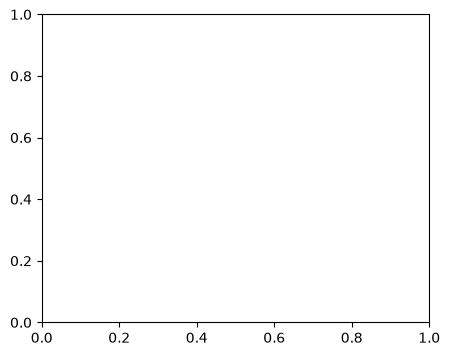

In [16]:
import matplotlib.pyplot as plt
import numpy as np


fig, ax = plt.subplots(figsize=(5,4))
cax = ax.matshow(cm, cmap='Blues')
fig.colorbar(cax)

labels = ['Human', 'AI']
ax.set_xticklabels([''] + labels)
ax.set_yticklabels([''] + labels)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Confusion Matrix')


for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', color='black')

plt.tight_layout()
plt.savefig('../results/confusion_matrix.png', dpi=300)
plt.show()